# Lab 06 — Data preparation and PCA

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Since Lecture 11 every NordicMart model received the same preparation: a few fixed recodes, then median imputation and
standardization inside a pipeline. Lecture 15 opened that box. Today we **rebuild the preparation piece by piece from the raw
table**, replace one piece at a time and measure what changes — the ablation method of Lab 5 — and then we compute and use
**PCA**.

| # | Step | Where |
|---|---|---|
| 1 | The preparation as **one estimator**: `ColumnTransformer` + `Pipeline`; what it learns; leakage | A |
| 2 | Encodings of `tier`: right order, alphabetical order, one-hot | B |
| 3 | **Who needs scaling**: five models × four scalers; a skewed attribute | C |
| 4 | Missing values: imputers, indicators, dropping rows | D |
| 5 | PCA by hand and with `scikit-learn`; how many components; loadings; PCA before a classifier | E |
| ★ | Leakage made visible; a model-based imputer; compression of images; PCA before trees | F |

- **Part A (≈ 25 min)** — the template of Lecture 15, opened up.
- **Part B (≈ 15 min)** — categorical attributes.
- **Part C (≈ 20 min)** — scaling and transformations.
- **Part D (≈ 15 min)** — missing values.
- **Part E (≈ 30 min)** — PCA.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (as in Labs 1–5)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- Every comparison is made with **cross-validation on the training part**, on the **same folds** (paired differences, Lab 5).
  Today we choose no final model, so the test set stays closed.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the encoders, scalers and transformers of `sklearn.preprocessing`, `make_column_transformer`, the imputers
(`SimpleImputer`, `KNNImputer`), `PCA`, and the digits of Lecture 14.

This time the split is made on the **raw** table: all the columns, `customer_id` and `postcode` included, `tier` as a string.
The function `recode` applies the **fixed** steps of the EDA log (Lecture 6): rules decided by us, that do not look at
other records, so they can be applied before the split and to each part separately. Everything **learned** from the data
(medians, means, standard deviations, the list of categories, the PCA directions) will go inside a pipeline.

The function `compare` is the `ablation` function of Lab 5: the first variant is the baseline, every other variant is
compared with it **fold by fold**. Run the cells, do not change them.

In [1]:
from pathlib import Path
import time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler,
                                   FunctionTransformer, PowerTransformer)
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.datasets import load_digits
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


In [2]:
df = pd.read_csv(NORDICMART_FILE)
X = df.drop(columns="churned")                      # raw attributes, nothing removed
y = df["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def recode(X):                                     # FIXED steps of the EDA log (Lecture 6): nothing learned from data
    return pd.DataFrame({
        "customer_id": X["customer_id"],
        "tier": X["tier"],                         # still a string: encoding is a learned step (Part B)
        "age": X["age"].replace(0, np.nan),
        "recency": X["days_since_last_buy"].replace(999, np.nan),
        "never_bought": (X["days_since_last_buy"] == 999).astype(int),
        "log_spend": np.log10(X["annual_spend"]),
        "sessions": X["web_sessions_month"].fillna(0),
        "store_only": X["web_sessions_month"].isna().astype(int),
        "tickets": X["tickets_90d"],
        "postcode": X["postcode"]}, index=X.index)

R_train = recode(X_train)

def compare(variants, y=y_train):                  # Lab 5, A1: paired comparison on the same folds
    scores = {name: cross_val_score(est, Xv, y, cv=cv_n, scoring="roc_auc") for name, (est, Xv) in variants.items()}
    base = next(iter(scores.values()))
    return pd.DataFrame({name: {"CV AUC": s.mean(), "std": s.std(), "diff": (s - base).mean(),
                                "std diff": (s - base).std(), "folds worse": int((s < base).sum())}
                         for name, s in scores.items()}).T.astype({"folds worse": int}).round(3)

print(f"training: {len(y_train)} customers, {y_train.sum()} churners | test: {len(y_test)} customers, {y_test.sum()} churners")
R_train.head()

training: 2100 customers, 252 churners | test: 900 customers, 108 churners


,customer_id,tier,age,recency,never_bought,log_spend,sessions,store_only,tickets,postcode
1308,C-1308,Basic,33.0,60.0,0,2.957,1.0,0,1,40100.0
2856,C-2856,Silver,62.0,61.0,0,2.743,3.0,0,1,40100.0
348,C-0348,Silver,54.0,56.0,0,2.417,0.0,1,0,40100.0
2250,C-2250,Basic,83.0,13.0,0,2.888,1.0,0,1,40100.0
343,C-0343,Silver,56.0,42.0,0,2.525,5.0,0,1,NaN


# Part A — The preparation as one estimator

## A1. The template of Lecture 15

Build the preparation of the slide *The whole preparation, in code*:

- a `ColumnTransformer` called `prep`, made with `make_column_transformer`, with two branches:
  - `tier` → `OrdinalEncoder(categories=[["Basic", "Silver", "Gold"]])`;
  - the numeric columns `num` (list below) → a pipeline `SimpleImputer(strategy="median")` + `StandardScaler()`;
  - pass `verbose_feature_names_out=False`, so that the output columns keep their original names;
- a pipeline `lr_prep = make_pipeline(prep, LogisticRegression(max_iter=1000))`.

Compute the five fold AUCs of `lr_prep` on `R_train` with `cv_n`, and their mean and standard deviation.

In [3]:
TIER_ORDER = [["Basic", "Silver", "Gold"]]
num = ["age", "recency", "never_bought", "log_spend", "sessions", "store_only", "tickets"]

In [4]:
# your code here


[0.816 0.87  0.828 0.761 0.841] -> CV AUC 0.823 ± 0.036


**Questions.**

1. `R_train` has 10 columns, `prep` lists 8 of them. What happens to `customer_id` and `postcode`? Is that what we want?
1. The tier is encoded as 0, 1, 2 and **not** standardized, all the other columns are. Does it matter for a logistic regression?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## A2. What the pipeline learned

Fit `lr_prep` on the whole `R_train`, then look inside it.

1. `lr_prep[0]` is the fitted `ColumnTransformer`; its branches are in `.named_transformers_` (print the keys).
   From the numeric branch print the **medians** learned by the imputer (`statistics_`) and the **means** and **standard
   deviations** learned by the scaler (`mean_`, `scale_`), as a small DataFrame indexed by `num`.
1. `lr_prep[0].get_feature_names_out()` gives the names of the columns that reach the model: use them to print the weights of
   the logistic regression (`lr_prep[-1].coef_[0]`) as a Series, sorted.
1. Two new customers arrive (cell below); the second one belongs to a tier introduced last week. Call
   `lr_prep.predict_proba(recode(new_customers))` inside a `try ... except ValueError as e: print(e)`, and read the error.
1. Build `lr_ohe`, equal to `lr_prep` but with `OneHotEncoder(handle_unknown="ignore")` for `tier`, fit it on `R_train`, and
   predict the two new customers.

In [5]:
new_customers = pd.DataFrame({"customer_id": ["C-9001", "C-9002"], "tier": ["Silver", "Platinum"], "age": [41, 37],
                              "days_since_last_buy": [12, 140], "annual_spend": [820.0, 2900.0],
                              "web_sessions_month": [6, np.nan], "tickets_90d": [0, 2], "postcode": [40100, 40100]})
new_customers

,customer_id,tier,age,days_since_last_buy,annual_spend,web_sessions_month,tickets_90d,postcode
0,C-9001,Silver,41,12,820.0,6.0,0,40100
1,C-9002,Platinum,37,140,2900.0,NaN,2,40100


In [6]:
# your code here


branches: ['ordinalencoder', 'pipeline', 'remainder']


,median (imputer),mean (scaler),std (scaler)
age,44.000,44.270,11.902
recency,32.000,48.977,51.868
never_bought,0.000,0.018,0.132
log_spend,2.761,2.776,0.324
sessions,2.000,2.050,2.067
store_only,0.000,0.177,0.381
tickets,0.000,0.599,0.782


,weight
sessions,-0.545
tier,-0.159
log_spend,-0.129
age,-0.084
never_bought,0.088
store_only,0.295
tickets,0.396
recency,0.895


ValueError: Found unknown categories ['Platinum'] in column 0 during transform
P(churn) of the new customers: [0.009 0.637]


**Questions.**

1. The median of `never_bought` and `store_only` is 0, the median of `sessions` is 2: are these imputers ever used?
   Which columns actually have missing values in `R_train`?
1. The weight of `tier` is negative. What does it say, and what would it say if Gold were coded 0 and Basic 2?
1. How does the one-hot pipeline represent a Platinum customer? Is that a sensible prediction, or only a prediction that does not crash?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## A3. Leakage: inside or outside the pipeline?

The rule of Lecture 15: a learned step fitted on all the data makes the estimate optimistic. Measure it on NordicMart.

1. **Leaky version**: `Z_leaky = prep.fit_transform(R_train)` (medians, means and standard deviations computed on *all* 2100
   customers), then the five fold AUCs of `LogisticRegression(max_iter=1000)` on `Z_leaky`.
1. **Correct version**: the five fold AUCs of `lr_prep` on `R_train` (already in `s_template`).
1. Print the five fold-by-fold differences.

In [7]:
# your code here


leaky    [0.8158 0.8695 0.8279 0.7614 0.841 ] 0.8231
pipeline [0.8158 0.8695 0.8279 0.7615 0.841 ] 0.8231
leaky - pipeline [ 0.0001  0.      0.     -0.0001 -0.0001]


**Question.** The difference is practically zero. Is the rule useless? When would the leaky version be far more optimistic?

**Answer.** *Write your answer here (double-click to edit).*

# Part B — Categorical attributes

## B1. Three encodings of `tier`

1. Compute the churn rate of each tier on the training part (`groupby`), in the order Basic, Silver, Gold.
1. Write a function `prep_with(tier_encoder)` that returns `prep` with a different encoder for `tier` (same numeric branch,
   `verbose_feature_names_out=False`).
1. With `compare`, evaluate three encodings — correct order (baseline), alphabetical order, one-hot — for three models:
   - `LogisticRegression(max_iter=1000)` on all the attributes;
   - `KNeighborsClassifier(51)` on all the attributes (the encoded tier must be standardized too: put the ordinal encoders in a
     pipeline with a `StandardScaler`);
   - `LogisticRegression(max_iter=1000)` on **`tier` only** (a `ColumnTransformer` with the tier branch only).

| encoding | encoder |
|---|---|
| ordinal, Basic < Silver < Gold | `OrdinalEncoder(categories=TIER_ORDER)` |
| ordinal, alphabetical | `OrdinalEncoder()` — Basic, Gold, Silver |
| one-hot | `OneHotEncoder(handle_unknown="ignore")` |

In [8]:
# your code here


,churn rate
tier,
Basic,0.167
Silver,0.081
Gold,0.034


CV AUC    std   diff  std diff  folds worse
logistic regression right order    0.823  0.036  0.000     0.000            0
                    alphabetical   0.822  0.035 -0.002     0.001            5
                    one-hot        0.822  0.035 -0.001     0.002            3
kNN, k=51           right order    0.802  0.040  0.000     0.000            0
                    alphabetical   0.797  0.040 -0.005     0.003            5
                    one-hot        0.801  0.040 -0.001     0.005            2
LR, tier only       right order    0.631  0.026  0.000     0.000            0
                    alphabetical   0.609  0.032 -0.021     0.014            5
                    one-hot        0.631  0.026  0.000     0.000            0

**Questions.**

1. With all the attributes, does the encoding matter? And with `tier` alone?
1. Why does the one-hot encoding get the same AUC as the right order, with `tier` alone?
1. Fit the logistic regression (all attributes) with the alphabetical order and with one-hot, and print the tier weights.
   Which of the two tells the business something true about the tiers?

In [9]:
# your code here


alphabetical  {'tier': -0.027}
one-hot       {'tier_Basic': 0.16, 'tier_Gold': -0.245, 'tier_Silver': 0.084}


**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

# Part C — Scaling and transformations

## C1. Who needs scaling

To see the effect of units, use the spend **in euros** (not in log) and the tier as 0, 1, 2. Build an all-numeric table:

```python
N_train = R_train[["tier"] + num].assign(tier=R_train["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2}),
                                         spend=X_train["annual_spend"]).drop(columns="log_spend")
```

Then compute the CV AUC (mean only, a DataFrame **models × scalers**) of the pipelines
`make_pipeline(SimpleImputer(strategy="median"), <scaler>, <model>)` — without the scaler for the column *none* — for:

| model | from |
|---|---|
| `KNeighborsClassifier(51)` | Lecture 11 |
| `SVC(C=10, gamma=0.001, class_weight="balanced")` | Lecture 12, best of the grid |
| `MLPClassifier((64,), alpha=1, max_iter=2000, random_state=0)` | Lecture 14, best of the grid |
| `LogisticRegression(max_iter=5000)` | Lecture 11 |
| `DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=0)` | Lecture 13 |

and the scalers *none*, `StandardScaler()`, `MinMaxScaler()`, `RobustScaler()`. Print first the standard deviation of each column of `N_train`.
It takes about 10 seconds (the MLP).

In [10]:
# your code here


,tier,age,recency,never_bought,sessions,store_only,tickets,spend
std,0.742,12.639,52.293,0.132,2.068,0.381,0.782,684.678


6 s


,none,standard,min-max,robust
kNN (k=51),0.721,0.799,0.794,0.796
SVM (RBF),0.634,0.821,0.780,0.824
"MLP (64, alpha=1)",0.779,0.823,0.812,0.824
logistic regression,0.822,0.821,0.818,0.822
tree,0.766,0.766,0.766,0.766


**Questions.**

1. Rank the five models from the most to the least sensitive to scaling, and explain each with the table *Who needs scaling* of Lecture 15.
1. The SVM without scaling falls to 0.63. Compute (roughly) the kernel value $\exp(-\gamma\|\mathbf{x}-\mathbf{x}'\|^2)$ for two customers whose
   spend differs by 500 euros, with $\gamma = 0.001$. What happens to the kernel matrix?
1. Logistic regression does not care about scaling here, although Lecture 15 lists it among the models that need it. Why?
1. Min-max is clearly worse than standard scaling for the SVM, not for the others. Any idea why? (Hint: where was `gamma = 0.001` chosen?)

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 
1. 

## C2. A skewed attribute

Spend has a long right tail (Lecture 15, *Transformations: skewed attributes*).

1. Print the skewness (`.skew()`) of the spend in euros, of its $\log_{10}$, and of the output of a `PowerTransformer()` fitted on it;
   print the exponent chosen by the power transformer (`lambdas_`).
1. With `compare`, evaluate logistic regression and kNN ($k$=51) on `N_train` with three treatments of `spend` — standardized only
   (baseline), $\log_{10}$ then standardized (`FunctionTransformer(np.log10)`), `PowerTransformer()` — and the other columns
   imputed and standardized as before (a `ColumnTransformer` with two branches).

In [11]:
# your code here


skewness: euros 2.57 | log10 0.10 | power 0.00 | lambda = -0.050


CV AUC    std   diff  std diff  \
logistic regression standardized           0.821  0.036  0.000     0.000   
                    log10 + standardized   0.823  0.036  0.002     0.001   
                    power transformer      0.823  0.036  0.002     0.001   
kNN, k=51           standardized           0.799  0.039  0.000     0.000   
                    log10 + standardized   0.802  0.040  0.003     0.010   
                    power transformer      0.801  0.036  0.002     0.007   

                                          folds worse  
logistic regression standardized                    0  
                    log10 + standardized            1  
                    power transformer               1  
kNN, k=51           standardized                    0  
                    log10 + standardized            3  
                    power transformer               2

**Questions.**

1. The power transformer chose $\lambda \approx -0.05$. Which transformation is that, approximately? (Box-Cox/Yeo-Johnson with $\lambda = 0$ is the logarithm.)
1. The gain of the transformation is small (+0.002 / +0.003). Why did we take the log in Lecture 6 anyway?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

# Part D — Missing values

## D1. What is missing, and does it matter?

1. Count the missing values per column in the **raw** `X_train`, plus the special values that `recode` turns into missing
   (age 0, `days_since_last_buy` 999).
1. Compute the churn rate of customers with and without `web_sessions_month`, and with and without `age`.

In [12]:
# your code here


,customer_id,tier,age,days_since_last_buy,annual_spend,web_sessions_month,tickets_90d,postcode,age == 0,days_since_last_buy == 999
missing / special,0,0,202,0,0,371,0,148,35,37


churn rate, sessions missing vs present: {False: 0.095, True: 0.237}
churn rate, age missing vs present:      {False: 0.12, True: 0.118}


**Answer.** *Write your answer here (double-click to edit).*

## D2. Undo the recode of `sessions`, and let the imputer do it

In Lecture 6 we replaced the missing sessions with 0 and added the flag `store_only` **by hand**. Suppose we had not done it:

```python
M_train = R_train.assign(sessions=X_train["web_sessions_month"]).drop(columns="store_only")
num_m = ["age", "recency", "never_bought", "log_spend", "sessions", "tickets"]
```

With `compare`, evaluate the logistic regression with the right tier order and these numeric branches:

| variant | data | numeric branch |
|---|---|---|
| recode of Lecture 6 (baseline) | `R_train` | `num_pipe` on `num` |
| median | `M_train` | `SimpleImputer(strategy="median")` + scaler, on `num_m` |
| mean | `M_train` | `SimpleImputer(strategy="mean")` + scaler |
| constant 0 | `M_train` | `SimpleImputer(strategy="constant", fill_value=0)` + scaler |
| median + indicator | `M_train` | `SimpleImputer(strategy="median", add_indicator=True)` + scaler |

In [13]:
# your code here


,CV AUC,std,diff,std diff,folds worse
recode of Lecture 6,0.823,0.036,0.000,0.000,0
median,0.795,0.032,-0.028,0.008,5
mean,0.792,0.030,-0.031,0.010,5
constant 0,0.817,0.038,-0.007,0.005,4
median + indicator,0.823,0.036,-0.001,0.001,3


**Questions.**

1. Explain the ranking median ≈ mean < constant 0 < median + indicator.
1. How many indicator columns does `add_indicator=True` add here, and for which attributes? (Fit `lr_imp(...)` and look at
   `get_feature_names_out()` of the numeric branch.)
1. In Lecture 15 the indicator changed nothing (0.823 with or without). Contradiction?

In [14]:
# your code here


array(['age', 'recency', 'never_bought', 'log_spend', 'sessions',
       'tickets', 'missingindicator_age', 'missingindicator_recency',
       'missingindicator_sessions'], dtype=object)

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## D3. Dropping rows

On `M_train` (sessions with missing values), drop the rows with at least one missing value in `num_m`. How many customers remain?
What is their churn rate, and what is the churn rate of the customers dropped?

In [15]:
# your code here


kept 1514 of 2100 | churn rate kept 0.096, dropped 0.181


**Answer.** *Write your answer here (double-click to edit).*

# Part E — PCA

## E1. PCA by hand, and with `scikit-learn`

PCA needs **all** attributes standardized, tier included. Use:

```python
prep_std = make_column_transformer((make_pipeline(OrdinalEncoder(categories=TIER_ORDER), StandardScaler()), ["tier"]),
                                   (num_pipe, num), verbose_feature_names_out=False)
```

1. `Z = prep_std.fit_transform(R_train)`; check that every column has mean 0 and standard deviation 1. Keep the column names in `names`.
1. **By hand** (Lecture 15, *The algorithm*): covariance matrix `S = np.cov(Z, rowvar=False)`; eigenvalues and eigenvectors with
   `np.linalg.eigh(S)` (it returns them in **increasing** order: sort them in decreasing order). Print the eigenvalues, their sum, and
   the trace of `S`.
1. **With `scikit-learn`**: `pca = PCA().fit(Z)`. Compare `pca.explained_variance_` with your eigenvalues, and `pca.components_` (one
   component per **row**) with your eigenvectors (one per **column**) — up to the sign.
1. Compute the **scores** by hand, `Z @ V`, and compare them with `pca.transform(Z)` (up to the sign of each column). What is the variance of each column of scores?

In [16]:
prep_std = make_column_transformer((make_pipeline(OrdinalEncoder(categories=TIER_ORDER), StandardScaler()), ["tier"]),
                                   (num_pipe, num), verbose_feature_names_out=False)

In [17]:
# your code here


means [-0.  0.  0.  0.  0.  0.  0.  0.] 
stds  [1. 1. 1. 1. 1. 1. 1. 1.]
eigenvalues [2.114 1.217 1.036 0.991 0.973 0.89  0.491 0.291] | sum 8.004 | trace 8.004
sklearn     [2.114 1.217 1.036 0.991 0.973 0.89  0.491 0.291]
max |difference| of the components, up to the sign: 0.0
max |difference| of the scores, up to the sign:    0.0
variance of the scores [2.114 1.217 1.036 0.991 0.973 0.89  0.491 0.291]


**Questions.**

1. Why is the sum of the eigenvalues 8 (up to rounding)?
1. Why can the signs of a component differ between your computation and `scikit-learn`, and why does it not matter?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## E2. How many components?

1. Print the explained variance ratio of each component and the cumulative ratio.
1. Draw the scree plot of Lecture 15: bars for each component, a line for the cumulative ratio, a dashed line at 90%.
1. How many components do these rules give: 90% of the variance; 95%; eigenvalue > 1 (Kaiser)?
   Check the first with `PCA(n_components=0.9).fit(Z).n_components_`.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
eigenvalue,2.114,1.217,1.036,0.991,0.973,0.890,0.491,0.291
ratio,0.264,0.152,0.129,0.124,0.122,0.111,0.061,0.036
cumulative,0.264,0.416,0.546,0.670,0.791,0.902,0.964,1.000


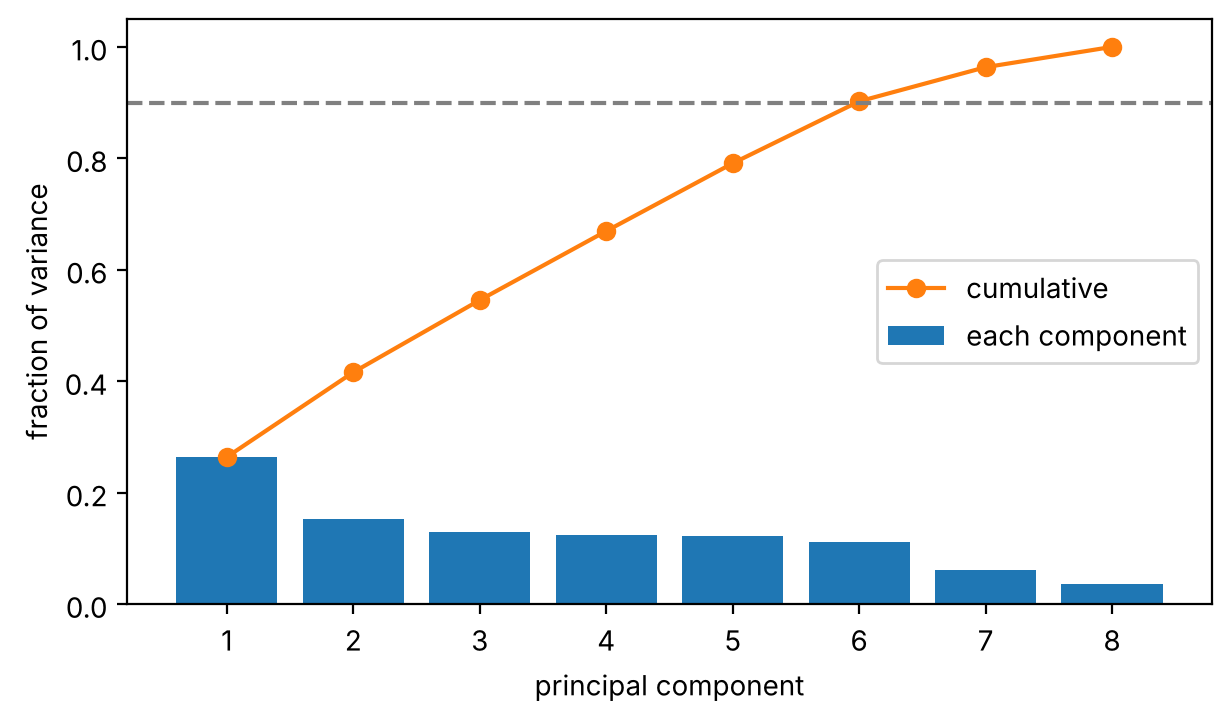

90%: 6 | 95%: 7 | Kaiser: 3 | PCA(0.9): 6


In [18]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## E3. Reading the components

1. Put the loadings of the first three components in a DataFrame (rows: attributes `names`, columns: PC1–PC3); flip the sign of each component
   so that its largest loading (in absolute value) is positive, as in the slides.
1. Scatter plot of the scores on PC1 and PC2 of the training customers, coloured by `y_train` (small, semi-transparent points;
   churners on top).
1. **Without standardization**: fit `PCA()` on `N_train` (spend in euros) after median imputation only. Print the explained variance
   ratio and the loadings of PC1.

,PC1,PC2,PC3
tier,0.57,0.26,-0.04
age,-0.02,-0.22,0.26
recency,-0.27,-0.25,-0.18
never_bought,0.01,0.11,0.73
log_spend,0.50,0.32,-0.04
sessions,0.54,-0.37,-0.00
store_only,-0.24,0.76,-0.03
tickets,-0.02,-0.04,0.60


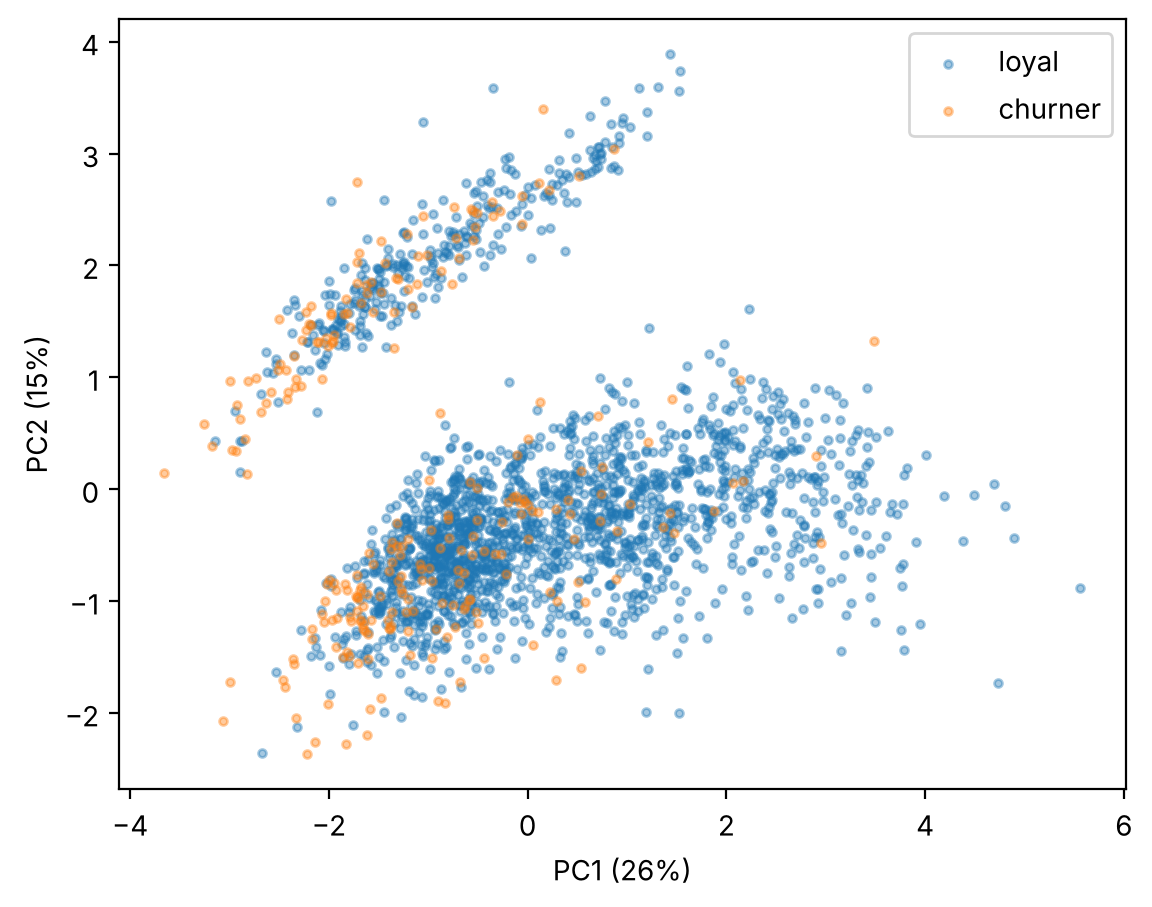

not standardized, ratio: [0.994 0.006 0.    0.    0.    0.    0.    0.   ]
PC1 loadings: {'tier': np.float64(0.001), 'age': np.float64(-0.001), 'recency': np.float64(-0.011), 'never_bought': np.float64(0.0), 'sessions': np.float64(0.001), 'store_only': np.float64(-0.0), 'tickets': np.float64(0.0), 'spend': np.float64(1.0)}


In [19]:
# your code here


**Questions.**

1. Give a name to PC1 and PC2 from their loadings. Which customers have a high score on PC1? On PC2?
1. In the scatter plot, where are the churners? Is PC1 alone enough to separate them?
1. What did PCA find without standardization, and why?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## E4. PCA before a classifier

PCA is a learned step: it goes **inside the pipeline**, after the preparation.

1. For $k = 1, \dots, 8$ compute the CV AUC of `make_pipeline(prep_std, PCA(k), <model>)` for `LogisticRegression(max_iter=1000)`
   and `KNeighborsClassifier(101)`; add the two models **without** PCA as a reference. Plot the two curves.
1. With `GridSearchCV` (scoring `"roc_auc"`, `cv=cv_n`) tune together `pca__n_components` in [2, 4, 6, 8] and
   `kneighborsclassifier__n_neighbors` in [51, 101, 201] for `make_pipeline(prep_std, PCA(), KNeighborsClassifier())`.
   Print the best parameters, the best score, and the whole grid as a table (`pivot` of `cv_results_`).

,1,2,3,4,5,6,7,8
logistic regression,0.759,0.757,0.756,0.766,0.794,0.823,0.823,0.823
kNN (k=101),0.746,0.751,0.772,0.766,0.788,0.807,0.803,0.801


{'logistic regression': np.float64(0.823), 'kNN (k=101)': np.float64(0.801)}


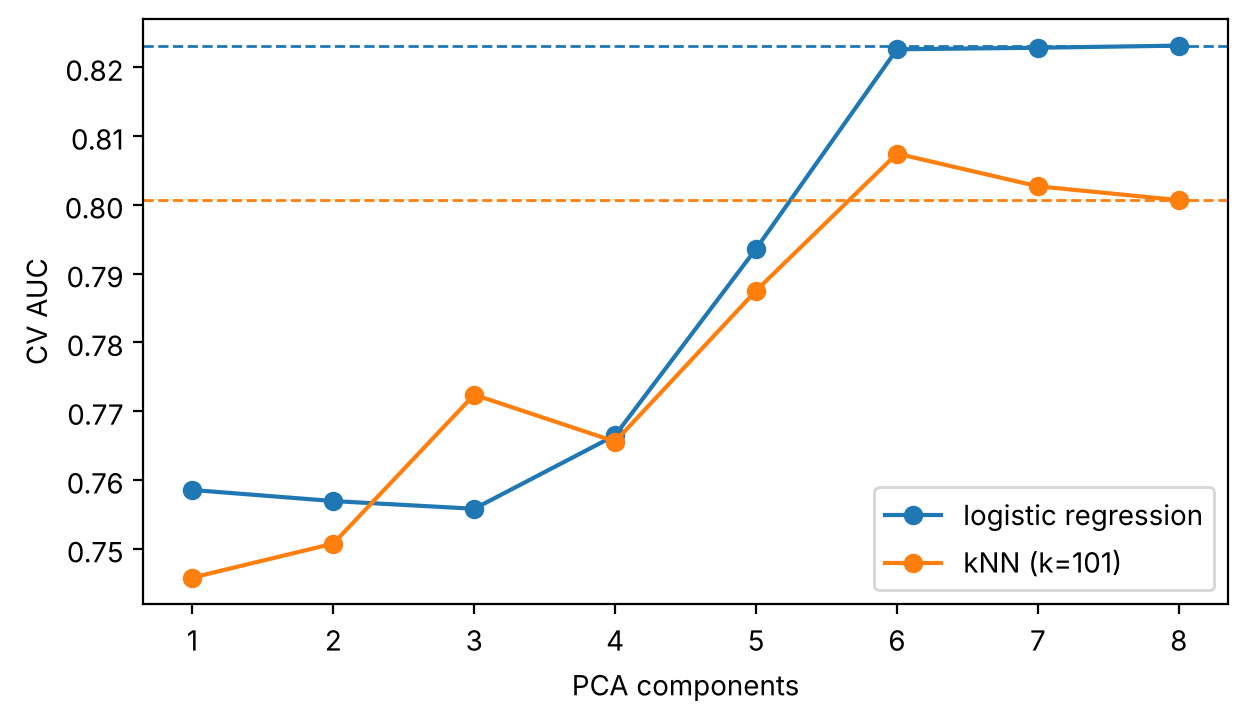

{'kneighborsclassifier__n_neighbors': 201, 'pca__n_components': 6} 0.81


param_kneighborsclassifier__n_neighbors,51,101,201
param_pca__n_components,,,
2,0.748,0.751,0.759
4,0.755,0.766,0.765
6,0.796,0.807,0.810
8,0.802,0.801,0.808


In [20]:
# your code here


**Questions.**

1. Does PCA help the logistic regression? Why do 6 components give exactly the AUC of all 8?
1. Does PCA help kNN? Is the difference meaningful (use `compare` on the best $k$NN with and without PCA if you are unsure)?
1. The 90% rule of E2 also said 6. Is that a reason to trust it?

In [21]:
# your code here


,CV AUC,std,diff,std diff,folds worse
"kNN 101, no PCA",0.801,0.034,0.000,0.00,0
"kNN 101, PCA 6",0.807,0.043,0.007,0.01,2


**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## E5. Where PCA pays off: the digits

The digits of Lecture 14: 1797 images of 8 × 8 pixels, 64 attributes in the **same unit** (grey level 0–16), so no standardization.

1. Load them with `load_digits(return_X_y=True)`. How many components keep 80%, 90%, 95% of the variance?
1. CV accuracy (`StratifiedKFold(5, shuffle=True, random_state=0)`) of `KNeighborsClassifier(3)` without PCA, and with
   `PCA(k)` before it, for $k$ in [2, 5, 10, 20, 30].

In [22]:
# your code here


{'80%': 13, '90%': 21, '95%': 29}


,no PCA,PCA 2,PCA 5,PCA 10,PCA 20,PCA 30
CV accuracy,0.988,0.599,0.919,0.976,0.985,0.986


**Answer.** *Write your answer here (double-click to edit).*

# Part F — Optional exercises ★

## F1. Leakage made visible ★

100 records, 5000 attributes of **pure noise**, a random class: no model can do better than 50% accuracy.

```python
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, size=100)
```

1. **Leaky**: select the 20 attributes most correlated with the class on all the data, `SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)`,
   then the 5-fold CV accuracy of a logistic regression on them.
1. **Correct**: the same, with `SelectKBest` inside the pipeline.

In [23]:
# your code here


leaky 0.87 | pipeline 0.50


**Answer.** *Write your answer here (double-click to edit).*

## F2. A model-based imputer ★

On `M_train` (Part D), replace the median imputer with `KNNImputer(n_neighbors=5)`, with and without `add_indicator=True`.
`KNNImputer` uses distances: put the `StandardScaler` **before** it (the scaler ignores missing values when it learns, and keeps them).
Compare with the median + indicator of D2.

In [24]:
# your code here


,CV AUC,std,diff,std diff,folds worse
median + indicator,0.823,0.036,0.000,0.000,0
kNN imputer,0.793,0.028,-0.029,0.010,5
kNN imputer + indicator,0.822,0.032,-0.001,0.005,1


**Answer.** *Write your answer here (double-click to edit).*

## F3. Compressing images ★

Reproduce the reconstruction figure of Lecture 15: for the first digit of `Xd`, fit `PCA(k)` on all the digits for $k$ in
[1, 2, 5, 10, 20, 40], and show the original image and the reconstructions `inverse_transform(transform(...))` as 8 × 8 images
(`imshow(..., cmap="gray_r")`). Print also the mean squared reconstruction error on all the digits for each $k$.

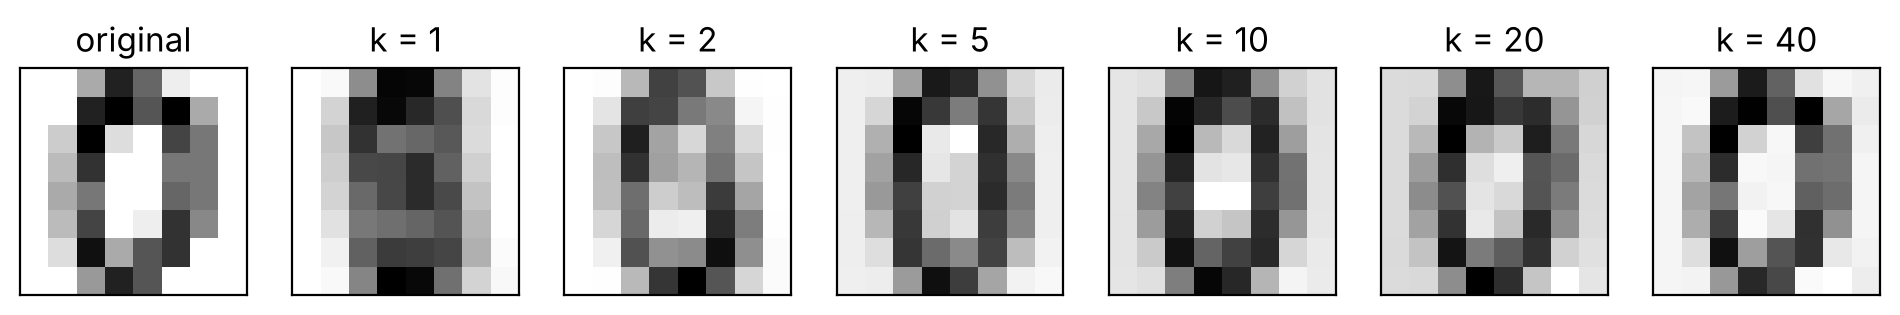

,1,2,5,10,20,40
mean squared error,15.98,13.42,8.54,4.91,1.98,0.22


In [25]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## F4. PCA before trees ★

With `compare`, evaluate the tree (depth 5, leaf 30) and the random forest of Lecture 13
(`RandomForestClassifier(n_estimators=300, max_features=1, min_samples_leaf=5, random_state=0, n_jobs=-1)`) on `R_train`, with `prep_std`
before them, with and without `PCA()` (all 8 components: a pure **rotation**, no information lost).

In [26]:
# your code here


CV AUC    std   diff  std diff  folds worse
tree          original axes    0.766  0.039  0.000     0.000            0
              rotated by PCA   0.765  0.025 -0.001     0.030            3
random forest original axes    0.812  0.028  0.000     0.000            0
              rotated by PCA   0.803  0.018 -0.010     0.018            3

**Answer.** *Write your answer here (double-click to edit).*

## Experiment log

Complete the log (double-click to edit): one row per comparison, with the CV AUC of the baseline, the difference of the variant
(mean over the five folds) and your verdict.

| Part | Model | Baseline | Variant | Δ CV AUC | Verdict |
|---|---|---|---|---|---|
| *A3* | *logistic regression* | *preparation in the pipeline (0.823)* | *preparation fitted before CV* | *0.000* | *same number, but keep the pipeline* |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test set was never used.

In [27]:
# quick self-check
assert len(X_test) == 900 and y_test.sum() == 108
assert round(s_template.mean(), 3) == 0.823
assert round(scaling.loc["kNN (k=51)", "none"], 3) == 0.721 and round(scaling.loc["kNN (k=51)", "standard"], 3) == 0.799
assert round(pca.explained_variance_[0], 3) == 2.114
assert round(pca_curve.loc[6, "logistic regression"], 3) == 0.823
print("ok")

ok
